# Exercise project 3 – SVM classification (SVC)

**Dataset:** HR Analytics – Job change of data scientists
https://www.kaggle.com/datasets/arashnic/hr-analytics-job-change-of-data-scientists

**Target variable:** `target` → 1 = the person is looking for a new job, 0 = not looking

In [ ]:
# usual imports in classic ML pipeline for Classification
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import svm
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# we need ADDITIONAL metrics ONLY for classification
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score

### STEP 1 - Load the data

In [2]:
# load the data
df = pd.read_csv("aug_train.csv")

# let's study the data
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


In [3]:
# how many rows in total do we have?
df.shape

(19158, 14)

### STEP 2: Basic data checks, duplicates or missing values (NaN)?

In [4]:
# enrollee_id is an identifier (meta-information), can't be used for machine learning purposes
# city has 123 different options (high cardinality),
# and city_development_index already describes the city with a number
df = df.drop(["enrollee_id", "city"], axis=1)

In [5]:
# missing values per column
(df.isna().mean() * 100).round(1)

city_development_index     0.0
gender                    23.5
relevent_experience        0.0
enrolled_university        2.0
education_level            2.4
major_discipline          14.7
experience                 0.3
company_size              31.0
company_type              32.0
last_new_job               2.2
training_hours             0.0
target                     0.0
dtype: float64

In [6]:
# columns with only a few missing values (less than 3%) => just drop those rows
df = df.dropna(subset=["enrolled_university", "education_level", "experience", "last_new_job"])

# columns with a lot of missing values => we would lose too much data by dropping the rows
# => fill the missing values with "Unknown" (it becomes its own category)
cols = ["gender", "major_discipline", "company_size", "company_type"]
df[cols] = df[cols].fillna("Unknown")

# good, no more missing values!
df.isna().sum()

city_development_index    0
gender                    0
relevent_experience       0
enrolled_university       0
education_level           0
major_discipline          0
experience                0
company_size              0
company_type              0
last_new_job              0
training_hours            0
target                    0
dtype: int64

In [7]:
# check duplicates
print(int(df.duplicated().sum()))

# remove duplicates
df = df.drop_duplicates()
len(df)

60


17954

***Case 1: Binary categories (only EXACTLY two options)***

In [8]:
# double-check whether relevent_experience-column is binary (exactly two options) or nominal (over 2 options)
df["relevent_experience"].value_counts()

relevent_experience
Has relevent experience    13137
No relevent experience      4817
Name: count, dtype: int64

In [9]:
# this just converts the value of column to 0 or 1
# 1 => Has relevent experience, 0 => No relevent experience
df["relevent_experience"] = (df["relevent_experience"] == "Has relevent experience").astype(int)

***Case 2: Ordinal categories (categories that have an order/rank => can be compared)***

In [10]:
# experience in years: "<1" => 0, ">20" => 21
df["experience"] = df["experience"].replace({"<1": "0", ">20": "21"}).astype(int)

# years since the last job change: "never" => 0, ">4" => 5
df["last_new_job"] = df["last_new_job"].replace({"never": "0", ">4": "5"}).astype(int)

# education level has a natural order
df["education_level"] = df["education_level"].map({"Primary School": 0, "High School": 1, "Graduate": 2, "Masters": 3, "Phd": 4})

# university enrollment: no_enrollment < part time < full time
df["enrolled_university"] = df["enrolled_university"].map({"no_enrollment": 0, "Part time course": 1, "Full time course": 2})

# company size has an order too
# Unknown => flag column (1 = size was unknown) + median value
size = {"<10": 0, "10/49": 1, "50-99": 2, "100-500": 3, "500-999": 4, "1000-4999": 5, "5000-9999": 6, "10000+": 7}
df["company_size_unknown"] = (df["company_size"] == "Unknown").astype(int)
df["company_size"] = df["company_size"].map(size)
df["company_size"] = df["company_size"].fillna(df["company_size"].median())

***Case 3: Nominal categories (categories that can't be compared numerically)***

In [11]:
# this makes multiple columns with the variable (Separate for yes/no)
from sklearn.preprocessing import OneHotEncoder

# list of our nominal categories
variables = ["gender", "major_discipline", "company_type"]

# use encoder
encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
one_hot_encoded = encoder.fit_transform(df[variables]).astype(int)
df = pd.concat([df, one_hot_encoded], axis=1).drop(columns=variables)

# target as integer (0/1)
df["target"] = df["target"].astype(int)

In [12]:
# let's check data again
df.head()

,city_development_index,relevent_experience,enrolled_university,education_level,experience,company_size,last_new_job,training_hours,target,company_size_unknown,...,major_discipline_Other,major_discipline_STEM,major_discipline_Unknown,company_type_Early Stage Startup,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,company_type_Unknown
0,0.920,1,0,2,21,3.0,1,36,1,1,...,0,1,0,0,0,0,0,0,0,1
1,0.776,0,0,2,15,2.0,5,47,0,0,...,0,1,0,0,0,0,0,0,1,0
2,0.624,0,2,2,5,3.0,0,83,0,1,...,0,1,0,0,0,0,0,0,0,1
4,0.767,1,0,3,21,2.0,4,8,0,0,...,0,1,0,0,1,0,0,0,0,0
5,0.764,1,1,2,11,3.0,1,24,1,1,...,0,1,0,0,0,0,0,0,0,1


**Check the balance of the data**

In [13]:
# how many people are looking for a new job? (0 = no, 1 = yes)
df["target"].value_counts(normalize=True)

target
0    0.754651
1    0.245349
Name: proportion, dtype: float64

<Axes: xlabel='target', ylabel='count'>

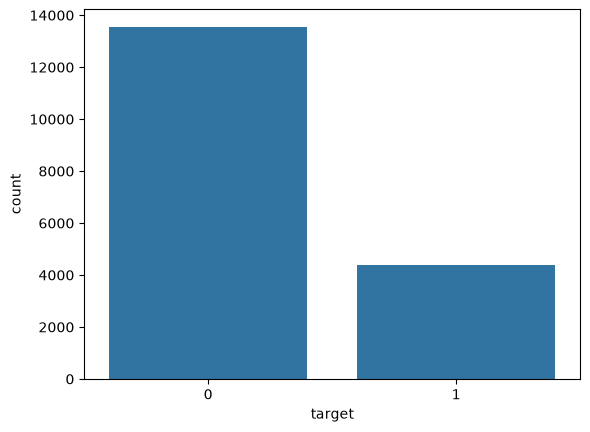

In [14]:
sns.countplot(x=df["target"])

In [15]:
# quick check on the correlation matrix, which variables
# affect the target variable?
df.corr()["target"].sort_values()

city_development_index             -0.336190
experience                         -0.176791
company_type_Pvt Ltd               -0.167421
relevent_experience                -0.135016
last_new_job                       -0.086191
gender_Male                        -0.066373
company_type_Funded Startup        -0.057588
major_discipline_Unknown           -0.050425
company_type_NGO                   -0.027278
training_hours                     -0.021931
company_size                       -0.021167
major_discipline_Humanities        -0.018124
company_type_Public Sector         -0.016091
education_level                    -0.013793
company_type_Early Stage Startup   -0.010322
major_discipline_Arts              -0.009811
company_type_Other                 -0.001580
major_discipline_No Major          -0.000017
gender_Other                        0.002060
major_discipline_Other              0.002473
major_discipline_Business Degree    0.004874
gender_Female                       0.008977
major_disc

### STEP 3: X/y and train/test -split

In [16]:
# first step, we split our data into SUPPORT variables and the TARGET variable
# a small trick => use everything else except, the target
X = df.drop("target", axis=1)

# our target variable is y
y = df["target"]

In [17]:
# create train/test split with scikit-learn's helper function
# 0.3 for testing => 30% of the data is reserved for testing purposes (used for metrics later)
# you can also define the random state, which is sometimes useful
# if you want to "lock down" all the randomness in this part to get same results every time
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

### STEP 4: Create and train the ML model

In [18]:
# SVM/SVC is easier to maintain when we use a pipeline + a scaler in front
# we have to switch SVC to probability=True, so that it uses probabilities instead
# of logits (~raw probability values, not in % -format)
model = make_pipeline(StandardScaler(), svm.SVC(probability=True, random_state=101))
model.fit(X_train, y_train)

/Users/pbengoec/Desktop/data_analytics/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](27,)","['city_development_index','relevent_experience','enrolled_university',..., 'company_type_Public Sector','company_type_Pvt Ltd', 'company_type_Unknown']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,27
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### STEP 5: Error and performance metrics

In [19]:
# we need to create test predictions based on our earlier reserved test dataset
# this data has never been seen by the model by now
predictions = model.predict(X_test)

In [20]:
# print the classification report based on true values and predictions
print(classification_report(y_test, predictions))

# get overall accuracy of the model and print it
acc = accuracy_score(y_test, predictions)
print("\nModel overall accuracy: {:.2f}%".format(acc * 100))

              precision    recall  f1-score   support

           0       0.82      0.91      0.86      4083
           1       0.57      0.36      0.45      1304

    accuracy                           0.78      5387
   macro avg       0.70      0.64      0.65      5387
weighted avg       0.76      0.78      0.76      5387


Model overall accuracy: 78.04%


<Axes: >

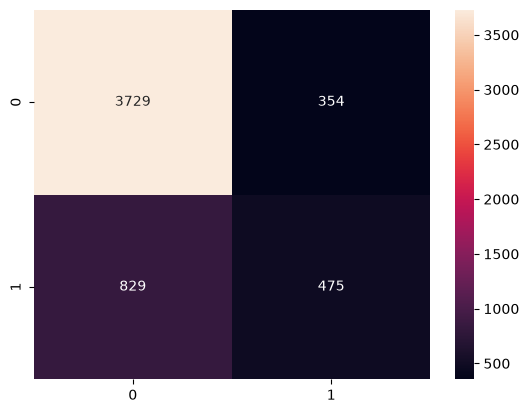

In [21]:
# see the confusion matrix
sns.heatmap(confusion_matrix(y_test, predictions), annot=True, fmt='g')

In [22]:
# The AUC score is a super sensitive metric
# you often get low scores, even 0.5

# A binary classifier is useful only when it achieves ROC-AUC score greater than 0.5 and as near to 1 as possible.
# If a classifier yields a score less than 0.5, it simply means that the model is performing worse
# than a random classifier, and therefore is useless.
# In multinomial logistic regression , AUC values are often interpreted as follows:
# 0.5-0.6 (failed)
# 0.6-0.7 (worthless)
# 0.7-0.8 (poor)
# 0.8-0.9 (good)
# > 0.9 (excellent)
roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

0.7724405134862644

In [23]:
# print out the exact probabilities for each class (first 5 test rows)
# first column => probability of 0 (No), second column => probability of 1 (Yes)
model.predict_proba(X_test)[:5].round(3)

array([[0.885, 0.115],
       [0.852, 0.148],
       [0.425, 0.575],
       [0.847, 0.153],
       [0.85 , 0.15 ]])

### Optimization: class_weight="balanced"

In [24]:
model_balanced = make_pipeline(StandardScaler(), svm.SVC(probability=True, class_weight="balanced", random_state=101))
model_balanced.fit(X_train, y_train)

/Users/pbengoec/Desktop/data_analytics/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](27,)","['city_development_index','relevent_experience','enrolled_university',..., 'company_type_Public Sector','company_type_Pvt Ltd', 'company_type_Unknown']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,27
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [25]:
# we need to create test predictions based on our earlier reserved test dataset
# this data has never been seen by the model by now
predictions = model_balanced.predict(X_test)

In [26]:
# print the classification report based on true values and predictions
print(classification_report(y_test, predictions))

# get overall accuracy of the model and print it
acc = accuracy_score(y_test, predictions)
print("\nModel overall accuracy: {:.2f}%".format(acc * 100))

              precision    recall  f1-score   support

           0       0.91      0.73      0.81      4083
           1       0.48      0.76      0.59      1304

    accuracy                           0.74      5387
   macro avg       0.69      0.75      0.70      5387
weighted avg       0.80      0.74      0.76      5387


Model overall accuracy: 74.03%


<Axes: >

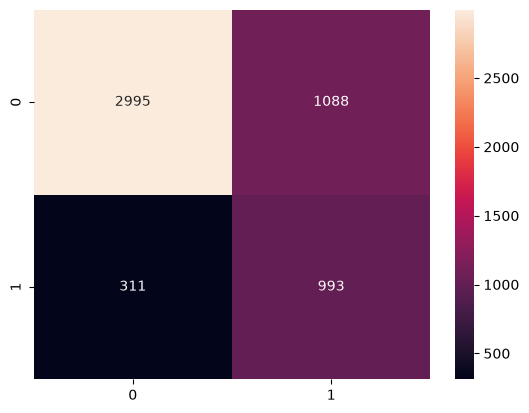

In [27]:
# see the confusion matrix
sns.heatmap(confusion_matrix(y_test, predictions), annot=True, fmt='g')

In [28]:
# The AUC score is a super sensitive metric
# you often get low scores, even 0.5

# A binary classifier is useful only when it achieves ROC-AUC score greater than 0.5 and as near to 1 as possible.
# If a classifier yields a score less than 0.5, it simply means that the model is performing worse
# than a random classifier, and therefore is useless.
# In multinomial logistic regression , AUC values are often interpreted as follows:
# 0.5-0.6 (failed)
# 0.6-0.7 (worthless)
# 0.7-0.8 (poor)
# 0.8-0.9 (good)
# > 0.9 (excellent)
roc_auc_score(y_test, model_balanced.predict_proba(X_test)[:, 1])

0.7852981425302278

In [29]:
# print out the exact probabilities for each class (first 5 test rows)
# first column => probability of 0 (No), second column => probability of 1 (Yes)
model_balanced.predict_proba(X_test)[:5].round(3)

array([[0.904, 0.096],
       [0.893, 0.107],
       [0.485, 0.515],
       [0.894, 0.106],
       [0.768, 0.232]])

### Comparison with project 2 (logistic regression)
Same data and same train/test split (random_state=101).

| Model | Accuracy | Recall (class 1) | F1 (class 1) | ROC-AUC |
|---|---|---|---|---|
| Logistic regression (project 2) | 0.77 | 0.25 | 0.34 | 0.78 |
| Logistic regression, `class_weight="balanced"` (project 2) | 0.73 | 0.77 | 0.58 | 0.78 |
| SVC | 0.78 | 0.36 | 0.45 | 0.77 |
| SVC, `class_weight="balanced"` | 0.74 | 0.76 | 0.59 | 0.79 |

### STEP 6: Testing/using the model in practice (inference)

In [30]:
df.columns

Index(['city_development_index', 'relevent_experience', 'enrolled_university',
       'education_level', 'experience', 'company_size', 'last_new_job',
       'training_hours', 'target', 'company_size_unknown', 'gender_Female',
       'gender_Male', 'gender_Other', 'gender_Unknown',
       'major_discipline_Arts', 'major_discipline_Business Degree',
       'major_discipline_Humanities', 'major_discipline_No Major',
       'major_discipline_Other', 'major_discipline_STEM',
       'major_discipline_Unknown', 'company_type_Early Stage Startup',
       'company_type_Funded Startup', 'company_type_NGO', 'company_type_Other',
       'company_type_Public Sector', 'company_type_Pvt Ltd',
       'company_type_Unknown'],
      dtype='str')

In [31]:
# let's create a Python -dictionary, containing our test values
# THE VARIABLE NAMES HAVE TO MATCH WITH THE COLUMNS OF X
# an imaginary person: lives in a city with a low development index, 5 years of experience,
# Graduate, STEM, works in a small private company, changed job 1 year ago
tester_row = {
    "city_development_index": 0.62,
    "relevent_experience": 1,        # 1 = has relevant experience
    "enrolled_university": 0,        # 0 no, 1 part time, 2 full time
    "education_level": 2,            # 0 primary, 1 high school, 2 graduate, 3 masters, 4 phd
    "experience": 5,                 # years
    "company_size": 1,               # 0 <10, 1 10/49, 2 50-99, ... 7 10000+
    "last_new_job": 1,               # years since last job change (0 = never)
    "training_hours": 40,
    "company_size_unknown": 0,
    "gender_Male": 1,
    "major_discipline_STEM": 1,
    "company_type_Pvt Ltd": 1,
}

# convert to pandas format
# reindex adds all the missing columns with 0 and puts them in the same order as X
tester_row = pd.DataFrame([tester_row]).reindex(columns=X.columns, fill_value=0)


print("All probabilities by category:")
print(model_balanced.predict_proba(tester_row))
print()

# change these based on your original data / target variable
labels = ["No", "Yes"]

print("Is this person looking for a new job (No/Yes):")
result = labels[model_balanced.predict(tester_row)[0]]
print(result)
print("-------------------")

All probabilities by category:
[[0.46769794 0.53230206]]

Is this person looking for a new job (No/Yes):
Yes
-------------------
